# 01 — What does a sound look like to a computer?

Goal of this notebook: go from **a sound you can hear** to **the picture our model will look at**,
one step at a time, and see *why* each step exists.

`waveform  →  spectrogram  →  mel spectrogram  →  log-mel spectrogram`

In [2]:
import sys; sys.path.insert(0, "..")          # so we can import our own src/ package
import numpy as np, matplotlib.pyplot as plt, librosa, librosa.display
from IPython.display import Audio
from src import audio
from src.datasets import esc50_meta

meta = esc50_meta()
print(len(meta), "clips,", meta.category.nunique(), "classes")
meta.head()

2000 clips, 50 classes


,path,fold,target,category
0,D:\sem7\MachineLearning\project\data\ESC-50-ma...,1,0,dog
1,D:\sem7\MachineLearning\project\data\ESC-50-ma...,1,14,chirping_birds
2,D:\sem7\MachineLearning\project\data\ESC-50-ma...,1,36,vacuum_cleaner
3,D:\sem7\MachineLearning\project\data\ESC-50-ma...,1,36,vacuum_cleaner
4,D:\sem7\MachineLearning\project\data\ESC-50-ma...,1,19,thunderstorm


## 1. The waveform

A microphone measures air pressure many times per second. At **16,000 samples per second**
(16 kHz), a 5 s clip is just **80,000 numbers** between -1 and 1. That's all a computer receives.

In [3]:
dog = meta[meta.category == "dog"].path.iloc[0]
wave = audio.load(dog)
print(wave.shape, "samples =", len(wave) / audio.SAMPLE_RATE, "seconds")
Audio(wave, rate=audio.SAMPLE_RATE)

(80000,) samples = 5.0 seconds


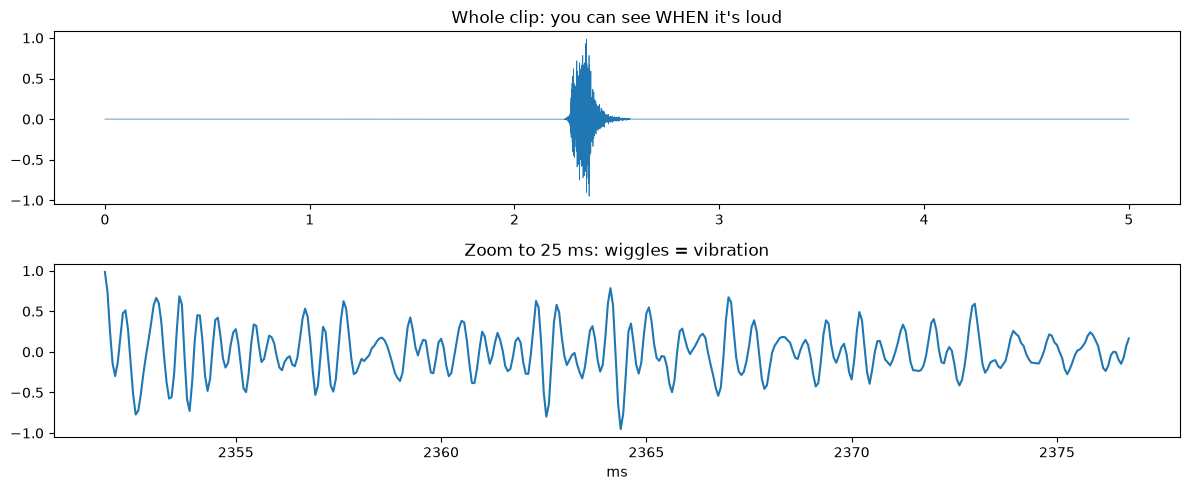

In [4]:
t = np.arange(len(wave)) / audio.SAMPLE_RATE
fig, ax = plt.subplots(2, 1, figsize=(12, 5))
ax[0].plot(t, wave, lw=0.5); ax[0].set_title("Whole clip: you can see WHEN it's loud")
i = np.argmax(np.abs(wave)); zoom = slice(i, i + 400)          # 400 samples = 25 ms
ax[1].plot(t[zoom] * 1000, wave[zoom]); ax[1].set_title("Zoom to 25 ms: wiggles = vibration")
ax[1].set_xlabel("ms"); plt.tight_layout()

**Why not feed these 80,000 numbers straight into a model?**
- The *same* bark shifted by 1 ms produces completely different numbers at every position.
- What identifies a sound is **which frequencies (pitches) vibrate**, and that's hidden in the wiggles.

So we ask a different question: *at each moment, how much of each frequency is present?*

## 2. The spectrogram (Fourier transform)

Take a 25 ms slice. The **Fourier transform** splits it into the frequencies it's made of,
like a prism splitting light into colours. Slide the slice along 10 ms at a time and stack the
results, and you get an image:

- x = time, y = frequency, colour = energy.

This is the **STFT** (short-time Fourier transform).

spectrogram shape (freq bins, time frames): (201, 501)


Text(0.5, 1.0, 'Same thing in decibels (log): now you see it')

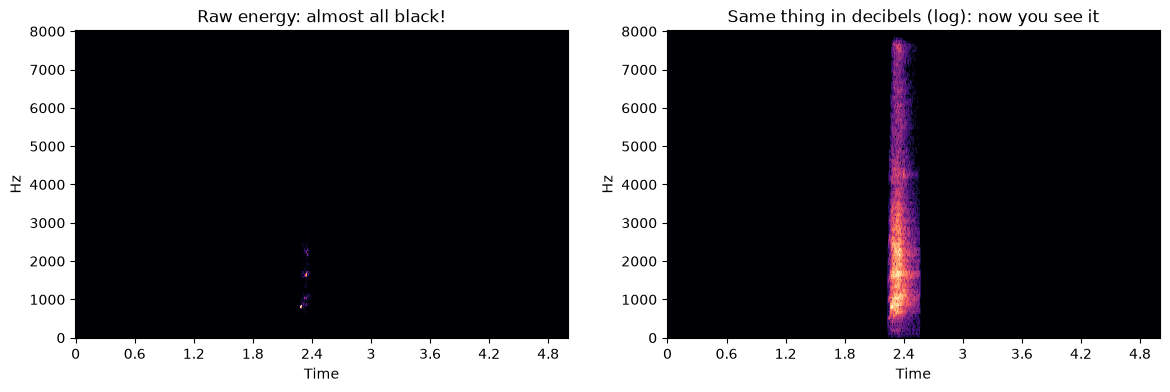

In [5]:
stft = np.abs(librosa.stft(wave, n_fft=audio.N_FFT, hop_length=audio.HOP_LENGTH)) ** 2
print("spectrogram shape (freq bins, time frames):", stft.shape)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
librosa.display.specshow(stft, sr=audio.SAMPLE_RATE, hop_length=audio.HOP_LENGTH,
                         x_axis="time", y_axis="linear", ax=ax[0])
ax[0].set_title("Raw energy: almost all black!")
librosa.display.specshow(librosa.power_to_db(stft), sr=audio.SAMPLE_RATE,
                         hop_length=audio.HOP_LENGTH, x_axis="time", y_axis="linear", ax=ax[1])
ax[1].set_title("Same thing in decibels (log): now you see it")

**Why the log (decibels)?** Energy values span a huge range. A bark can be 10,000× more energetic
than the background, so on a linear scale everything except the loudest bit looks black. Ears
also work logarithmically: each doubling of energy sounds like about the same step up in
loudness.

## 3. Mel scale: squash frequency the way ears do

We hear the difference between 100 Hz and 200 Hz easily, but 7,100 Hz vs 7,200 Hz sounds almost
the same. The **mel scale** merges the 201 frequency bins into **64 bands**: narrow bands at low
pitch, wide bands at high pitch. It keeps the detail we can hear, and the model gets a smaller
picture to learn from.

This is `audio.log_mel()`, the exact function the model, the notebooks and the website all use.

log-mel shape (mel bands, frames): (64, 501)  ← this 'image' is what the CNN will see


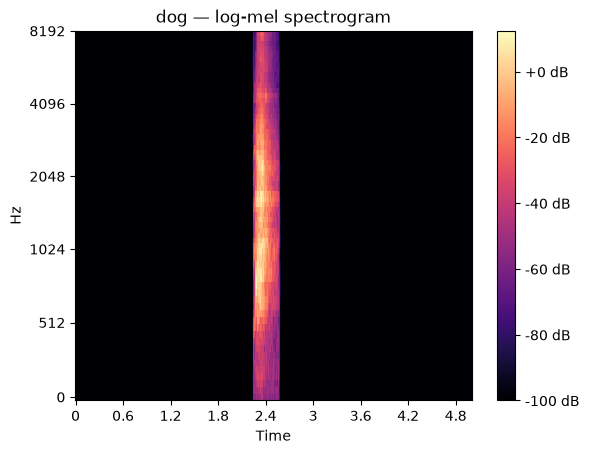

In [6]:
lm = audio.log_mel(wave)
print("log-mel shape (mel bands, frames):", lm.shape, " ← this 'image' is what the CNN will see")
librosa.display.specshow(lm, sr=audio.SAMPLE_RATE, hop_length=audio.HOP_LENGTH,
                         x_axis="time", y_axis="mel")
plt.colorbar(format="%+.0f dB"); plt.title("dog — log-mel spectrogram");

## 4. Different sounds, different pictures

If a *human* can tell these pictures apart by eye, a model has a chance too. Notice:
- **dog**: short separate bursts
- **rain / vacuum**: continuous texture
- **siren**: a line sweeping up and down in pitch
- **keyboard**: tiny vertical clicks

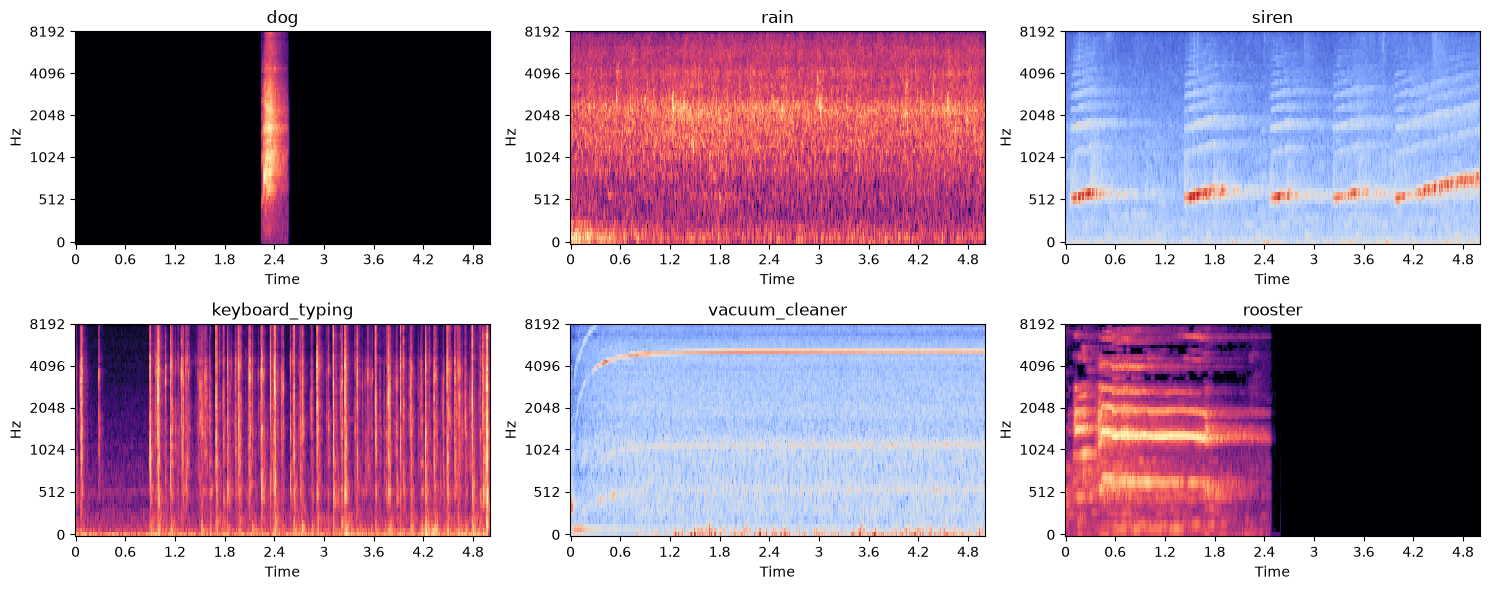

In [7]:
classes = ["dog", "rain", "siren", "keyboard_typing", "vacuum_cleaner", "rooster"]
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, c in zip(axes.flat, classes):
    w = audio.load(meta[meta.category == c].path.iloc[0])
    librosa.display.specshow(audio.log_mel(w), sr=audio.SAMPLE_RATE,
                             hop_length=audio.HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(c)
plt.tight_layout()

## 5. The folds (why we don't shuffle)

ESC-50 comes pre-split into 5 folds of 400 clips. Several clips were cut from the **same original
recording** (same dog, same room), and those always sit in the same fold.

If we shuffled randomly, the model could be tested on a clip from a recording it trained on. It
would score well by *recognising the recording*, not the sound. That's **data leakage**, and it's
why every score in this project uses these folds.

In [8]:
meta.groupby("fold").size()

fold
1    400
2    400
3    400
4    400
5    400
dtype: int64

## What's next

`python -m src.baseline` summarises each clip into 80 numbers (MFCC mean/spread) and trains
classic models on them. That's the **simple approach**, and its score is the bar our own CNN has
to beat.

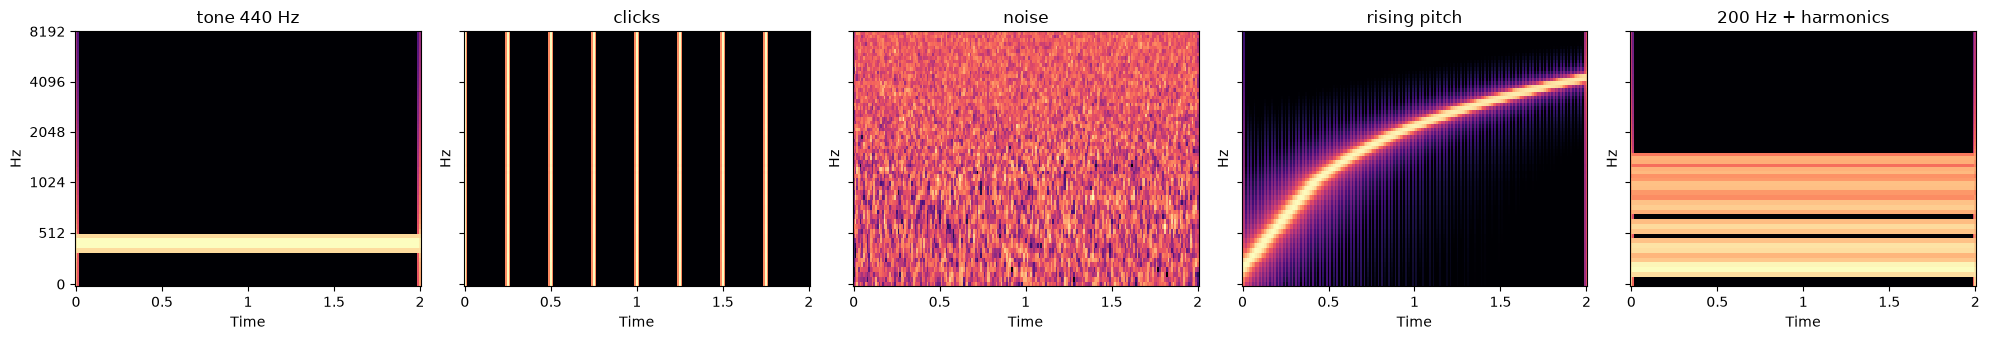

tone 440 Hz


clicks


noise


rising pitch


200 Hz + harmonics


In [9]:
  import numpy as np, matplotlib.pyplot as plt, librosa.display
  from IPython.display import Audio, display
  from src.audio import log_mel, SAMPLE_RATE, HOP_LENGTH

  sr = SAMPLE_RATE
  t = np.arange(2 * sr) / sr                     # 2 seconds of time stamps

  clicks = np.zeros_like(t); clicks[:: sr // 4] = 1.0          # 4 clicks per second
  sounds = {
      "tone 440 Hz":        0.5 * np.sin(2 * np.pi * 440 * t),              # steady whistle
      "clicks":             clicks,
      "noise":              0.1 * np.random.randn(len(t)),                  # like rain / hiss
      "rising pitch":       0.5 * np.sin(2 * np.pi * (200 * t + 1000 * t**2)),  # siren-ish
      "200 Hz + harmonics": sum(0.3 / k * np.sin(2 * np.pi * 200 * k * t) for k in range(1, 8)),  # voice-ish
  }

  fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
  for ax, (name, w) in zip(axes, sounds.items()):
      librosa.display.specshow(log_mel(w.astype(np.float32)), sr=sr, hop_length=HOP_LENGTH,
                               x_axis="time", y_axis="mel", ax=ax, cmap="magma")
      ax.set_title(name)
  plt.tight_layout(); plt.show()

  for name, w in sounds.items():                 # listen while you look
      print(name); display(Audio(w, rate=sr))


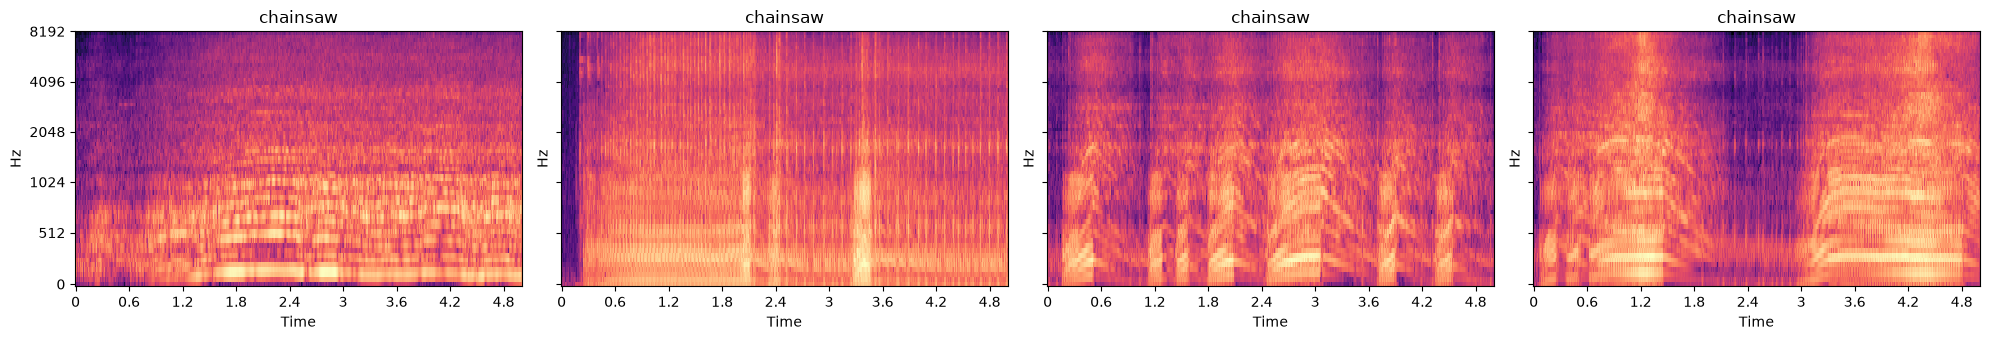

In [21]:
CATEGORY = "chainsaw"          # try: "cat", "siren", "rain", "clock_tick", "crow", "chainsaw" ...
N = 4                     # how many different clips to show

clips = meta[meta.category == CATEGORY].head(N)
fig, axes = plt.subplots(1, N, figsize=(5 * N, 3.5), sharey=True)
for ax, p in zip(axes, clips.path):
  librosa.display.specshow(audio.log_mel(audio.load(p)), sr=audio.SAMPLE_RATE,
                           hop_length=audio.HOP_LENGTH, x_axis="time", y_axis="mel",
                           ax=ax, cmap="magma")
  ax.set_title(CATEGORY)
plt.tight_layout(); plt.show()

for p in clips.path:      # listen along, left to right
  display(Audio(audio.load(p), rate=audio.SAMPLE_RATE))